In [2]:
from anemone.inversion import Resistivity
import torch

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

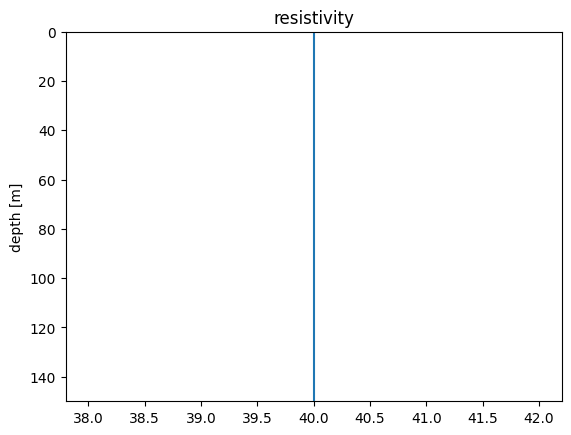

In [4]:
res = Resistivity.smooth(torch.ones(31)*40, torch.logspace(-0.1, 2, 30))
res.plot()

In [7]:
# Let's examine the key attributes for plotting
print("Values (resistivity):")
print(f"  Type: {type(res.values)}")
print(f"  Length: {len(res.values)}")
print(f"  First element: {res.values[0]}")
print(f"  First element type: {type(res.values[0])}")
print(f"  First element shape: {res.values[0].shape}")

print(f"\nZ (depth):")
print(f"  Type: {type(res.z)}")
print(f"  Shape: {res.z.shape}")
print(f"  Values: {res.z}")

# Get the actual resistivity and depth data as numpy arrays
resistivity_data = res.values[0].detach().numpy()  # Convert torch tensor to numpy
depth_data = res.z.detach().numpy()  # Convert torch tensor to numpy

print(f"\nExtracted data:")
print(f"  Resistivity shape: {resistivity_data.shape}")
print(f"  Depth shape: {depth_data.shape}")
print(f"  Resistivity values: {resistivity_data[:5]}...")
print(f"  Depth values: {depth_data[:5]}...")

Values (resistivity):
  Type: <class 'list'>
  Length: 1
  First element: tensor([40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40., 40.,
        40., 40., 40.])
  First element type: <class 'torch.Tensor'>
  First element shape: torch.Size([31])

Z (depth):
  Type: <class 'torch.Tensor'>
  Shape: torch.Size([30])
  Values: tensor([  0.7943,   0.9385,   1.1087,   1.3099,   1.5476,   1.8284,   2.1601,
          2.5521,   3.0152,   3.5622,   4.2086,   4.9722,   5.8744,   6.9403,
          8.1996,   9.6874,  11.4451,  13.5218,  15.9753,  18.8739,  22.2985,
         26.3445,  31.1246,  36.7720,  43.4441,  51.3269,  60.6399,  71.6428,
         84.6421, 100.0000])

Extracted data:
  Resistivity shape: (31,)
  Depth shape: (30,)
  Resistivity values: [40. 40. 40. 40. 40.]...
  Depth values: [0.7943282 0.9384557 1.1087345 1.3099097 1.5475873]...


In [9]:
import plotly.graph_objects as go
import plotly.express as px
import numpy as np

# Create the Plotly version of the resistivity plot
# Since we have 31 resistivity values and 30 depth values, this suggests
# we have layer boundaries and need to create a step plot

# For a proper resistivity plot, we typically plot resistivity vs depth
# with steps to show the layer structure

fig = go.Figure()

# Create depth boundaries - we need to extend the depth array
# Typically depth[0] represents the surface (0m) and we extend to show the bottom layer
depth_boundaries = np.concatenate([[0], depth_data])

# Add the step plot for resistivity
fig.add_trace(go.Scatter(
    x=resistivity_data,
    y=depth_boundaries,
    mode='lines',
    line=dict(shape='hv', width=2, color='blue'),  # 'hv' creates step-like horizontal-vertical lines
    name='Resistivity Model',
    fill=None
))

# Update layout to match typical resistivity plot conventions
fig.update_layout(
    title='Resistivity Model',
    xaxis_title='Resistivity (Ω⋅m)',
    yaxis_title='Depth (m)',
    xaxis_type='log',  # Resistivity is typically plotted on log scale
    yaxis=dict(autorange='reversed'),  # Depth increases downward
    width=800,
    height=600,
    showlegend=True
)

# Add grid
fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgray')
fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgray')

fig.show()

In [11]:
# Enhanced version with filled areas and color mapping
fig_enhanced = go.Figure()

# Create a more detailed visualization with filled rectangles for each layer
for i in range(len(depth_data)):
    # Define the boundaries for each layer
    top_depth = depth_boundaries[i] if i == 0 else depth_boundaries[i]
    bottom_depth = depth_boundaries[i+1]
    resistivity_val = resistivity_data[i]
    
    # Add a filled rectangle for each layer
    fig_enhanced.add_trace(go.Scatter(
        x=[resistivity_val, resistivity_val, resistivity_val, resistivity_val, resistivity_val],
        y=[top_depth, bottom_depth, bottom_depth, top_depth, top_depth],
        fill='tonexty' if i > 0 else 'tozeroy',
        mode='lines',
        line=dict(width=0),
        fillcolor=f'rgba({int(255*(i/len(depth_data)))}, {int(255*(1-i/len(depth_data)))}, 100, 0.3)',
        name=f'Layer {i+1}: {resistivity_val:.1f} Ω⋅m',
        showlegend=True
    ))

# Add the main resistivity curve
fig_enhanced.add_trace(go.Scatter(
    x=resistivity_data,
    y=depth_boundaries,
    mode='lines+markers',
    line=dict(shape='hv', width=3, color='red'),
    marker=dict(size=6, color='red'),
    name='Resistivity Profile',
    showlegend=True
))

# Update layout
fig_enhanced.update_layout(
    title='Enhanced Resistivity Model Visualization',
    xaxis_title='Resistivity (Ω⋅m)',
    yaxis_title='Depth (m)',
    xaxis_type='log',
    yaxis=dict(autorange='reversed'),
    width=900,
    height=700,
    showlegend=True,
    legend=dict(
        orientation="v",
        yanchor="top",
        y=1,
        xanchor="left",
        x=1.02
    )
)

# Add grid and styling
fig_enhanced.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgray', minor=dict(showgrid=True))
fig_enhanced.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgray', minor=dict(showgrid=True))

fig_enhanced.show()

In [18]:
from panels import *

In [ ]:
@dataclass
class StartingModelSettings(PanelSettings):
    default_res: float = 40.0  # Default resistivity value
    line_color: str='#ff0000'


class StartingModel(ModelGraph):
    def __init__(self, data, **kwargs):
        settings = StartingModelSettings(id='starting_model', **kwargs)
        super().__init__(id='starting_model', settings=settings)
        self.data = data

    def render(self):
        # Add the step plot for resistivity
        fig = px.scatter(self.data,
            x='resistivity',
            y='depth'
        )

        # Update layout to match typical resistivity plot conventions
        fig.update_layout(
            title='Resistivity Model',
            xaxis_title='Resistivity (Ω⋅m)',
            yaxis_title='Depth (m)',
            xaxis_type='log',  # Resistivity is typically plotted on log scale
            yaxis=dict(autorange='reversed'),  # Depth increases downward
            width=800,
            height=600,
            showlegend=True
        )

        # Add grid
        fig.update_xaxes(showgrid=True, gridwidth=1, gridcolor='lightgray')
        fig.update_yaxes(showgrid=True, gridwidth=1, gridcolor='lightgray')

        return fig
    
    def initialize(self):
        return html.Div([dcc.Graph(figure=self.render(), id=self.id, mathjax=True, 
                                   style={'height':'98%', 'width': '98%', 'align': 'center', 'pad': '10px'}),
                        dcc.Slider(id=f'slider-{self.id}', min=0, max=100, step=1, value=self.settings.default_res,
                                   marks={i: str(i) for i in range(0, 101, 10)},
                                   tooltip={"placement": "bottom", "always_visible": True})],
                        )
    
    def add_callbacks(self, app):
        super().add_callbacks(app)

        @app.callback(
            Output(self.id, 'figure'),
            Input(f'slider-{self.id}', 'value'),
            prevent_initial_call=True

        )
        def update_figure(slider_value):
            self.data['resistivity'] = slider_value
            return self.render()        

In [53]:
import pandas as pd

df = pd.DataFrame({
    'resistivity': [40.0] * 31,  # Default resistivity values
    'depth': np.linspace(0, 300, 31)  # Example depth values from 0 to 300 meters
})

x1 = StartingModel(df)
#x1.initialize()

In [54]:
import dash
from dash import Dash

app = Dash(__name__, suppress_callback_exceptions=True, assets_folder='assets')
app.title = "sea anemone"
app.layout = x1.initialize()
x1.add_callbacks(app)
app.run(debug=True, use_reloader=False)  # Set use_reloader=False to avoid double callbacks during development